# DSMarket — Predicción de ventas a 28 días sin la segmentación de producto

**Experimento complementario al notebook `03_Forecasting_DSMarket.ipynb`.**

El modelo final del notebook 03 incluye `grupo_producto` (los seis grupos del clustering, `02_Clustering_DSMarket.ipynb`) como variable categórica. Este notebook responde a una pregunta concreta: **¿qué aporta esa variable?** Para ello se repite el procedimiento íntegro **sin ella** y se comparan los resultados.

**Diseño del experimento**

- Se mantienen idénticos las ventanas de validación (feb, mar y abr de 2016, más nov y dic de 2015), los hiperparámetros y la semilla de LightGBM, la estrategia de cuatro modelos por bloques semanales, las variables de calendario, de precio y de rezagos, las variables de evento semanal y las métricas (WRMSSE, WAPE semanal).
- La **única diferencia** es que `grupo_producto` se retira de `FEATURES` y de `CATEGORICAS`.
- Se conservan `item_id`, `dept_id`, `cat_id`, `store_id` y `region_id`. Por tanto, el modelo sigue pudiendo identificar cada producto; lo que se retira es la agrupación de productos por comportamiento.
- Los grupos se utilizan únicamente **para analizar** el error (sección 5), no como entrada del modelo.
- Los resultados se guardan en `cache_forecast_sin_clusters/`, de modo que no se modifica la caché del notebook 03.

El entrenamiento está en `forecast_sin_clusters.py` (`python3 forecast_sin_clusters.py`); este notebook lo ejecuta si la caché no existe y presenta la comparación.

## 1. Configuración y datos

In [1]:
import os, gc, time, pickle, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')
import forecast_segmentacion as fs
import forecast_semanal as fw
import forecast_sin_clusters as sc

DSMARKET_NAVY = "#0a2a5c"; DSMARKET_BLUE = "#2a78d6"; DSMARKET_GOLD = "#eda100"; DSMARKET_GREEN = "#6a9f1f"
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9",
                                     "figure.facecolor": "white", "axes.facecolor": "white"})
plt.rcParams["axes.titlecolor"] = DSMARKET_NAVY
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option('display.max_columns', 60)

V_, P_, cs_, cal_, meta_, folds_ = fs.cargar()
sem_ = fw.variables_semanales(cal_)
V16 = fw.ventanas(cal_, folds_)
print(f"{V_.shape[0]:,} series x {V_.shape[1]} días")
print('Variables con clusters   :', fs.BASE + ['grupo_producto'] + fw.EXTRA_SEMANAL)
print('Variables sin clusters   :', fs.BASE + fw.EXTRA_SEMANAL)

30,490 series x 1913 días
Variables con clusters   : ['sell_price', 'weekday', 'month', 'day_of_month', 'week_of_year', 'is_weekend', 'event', 'lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'rmean_7', 'rmean_28', 'rmean_91', 'rmean_364', 'rstd_28', 'zero_frac_28', 'price_rel', 'price_chg', 'item_id', 'store_id', 'dept_id', 'cat_id', 'region_id', 'grupo_producto', 'sem_evento', 'evento_semana', 'dias_hasta_evento', 'dias_desde_evento']
Variables sin clusters   : ['sell_price', 'weekday', 'month', 'day_of_month', 'week_of_year', 'is_weekend', 'event', 'lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'rmean_7', 'rmean_28', 'rmean_91', 'rmean_364', 'rstd_28', 'zero_frac_28', 'price_rel', 'price_chg', 'item_id', 'store_id', 'dept_id', 'cat_id', 'region_id', 'sem_evento', 'evento_semana', 'dias_hasta_evento', 'dias_desde_evento']


## 2. Entrenamiento sin clusters

Se entrenan dos configuraciones en las cinco ventanas: el **modelo de la sección 6 del notebook 03** (180 días de historia, sin variables de evento semanal) y el **modelo final** (400 días con eventos semanales). Cada una requiere cuatro modelos por ventana. Si se desea repetir además las dos configuraciones intermedias, se establece `COMPLETO = True`.

El primer entrenamiento tarda entre 1 y 3 horas según la máquina; las ejecuciones posteriores leen la caché.

In [2]:
COMPLETO = False
configs = list(sc.CONFIGS_SC) if COMPLETO else ['actual', 'eventos_semanales_400d']
t0 = time.time()
res_sin = {}
for nombre, ventana in V16.items():
    for config in configs:
        res_sin[(config, nombre)] = sc.entrenar(config, nombre, ventana, V_, P_, cs_, cal_, meta_, sem_)
print(f"listo en {time.time()-t0:.0f}s")

listo en 1231s


## 3. Comparación con y sin clusters

Las dos versiones se evalúan con las mismas funciones y sobre las mismas ventanas. La versión con clusters se lee de la caché del notebook 03.

In [3]:
NOMBRE_CFG = {'actual': '180 días', 'eventos_semanales': '180 días + eventos sem.',
              'actual_400d': '400 días', 'eventos_semanales_400d': '400 días + eventos sem.'}
filas = []
for nombre, (s_, e_) in V16.items():
    y_ = V_[:, s_:e_].astype(np.float32); h_ = V_[:, :s_].astype(np.float32)
    for config in configs:
        con = fw.entrenar(config, nombre, (s_, e_), V_, P_, cs_, cal_, meta_, None)['pred']
        sin = res_sin[(config, nombre)]['pred']
        for variante, p in [('con clusters', con), ('sin clusters', sin)]:
            filas.append({'ventana': fw.NOMBRE_VENTANA[nombre], 'modelo': NOMBRE_CFG[config], 'variante': variante,
                          'WRMSSE': fs.wrmsse(y_, p, h_, P_[:, :s_]),
                          'WAPE semanal': fw.wape(fw.a_semanas(y_), fw.a_semanas(p))})
comp = pd.DataFrame(filas)
orden_v = [fw.NOMBRE_VENTANA[k] for k in V16]
for metrica in ['WRMSSE', 'WAPE semanal']:
    t = comp.pivot_table(index='ventana', columns=['modelo', 'variante'], values=metrica).reindex(orden_v)
    t.loc['media feb-abr'] = t.iloc[:3].mean()
    print(f'{metrica} (menor es mejor)'); display(t.round(4 if metrica == 'WRMSSE' else 2))

WRMSSE (menor es mejor)


modelo                      180 días              400 días + eventos sem.  \
variante                con clusters sin clusters            con clusters   
ventana                                                                     
Feb 2016                      1.0776       1.0799                  1.0756   
Mar 2016                      1.0415       1.0410                  1.0383   
Abr 2016                      1.0029       1.0055                  0.9994   
Nov 2015 (Thanksgiving)       1.0520       1.0542                  1.0177   
Dic 2015 (Navidad)            1.1119       1.1090                  1.0484   
media feb-abr                 1.0407       1.0422                  1.0378   

modelo                                
variante                sin clusters  
ventana                               
Feb 2016                      1.0758  
Mar 2016                      1.0384  
Abr 2016                      1.0002  
Nov 2015 (Thanksgiving)       1.0156  
Dic 2015 (Navidad)            1.0469  
media feb-abr                 1.0381

WAPE semanal (menor es mejor)


modelo                      180 días              400 días + eventos sem.  \
variante                con clusters sin clusters            con clusters   
ventana                                                                     
Feb 2016                       41.29        41.41                   40.73   
Mar 2016                       40.99        41.03                   40.07   
Abr 2016                       38.51        38.54                   37.83   
Nov 2015 (Thanksgiving)        45.18        45.51                   40.35   
Dic 2015 (Navidad)             47.37        47.60                   41.52   
media feb-abr                  40.26        40.33                   39.54   

modelo                                
variante                sin clusters  
ventana                               
Feb 2016                       40.74  
Mar 2016                       40.14  
Abr 2016                       37.76  
Nov 2015 (Thanksgiving)        40.39  
Dic 2015 (Navidad)             41.44  
media feb-abr                  39.54

Δ WRMSSE  \
ventana                 modelo                              
Abr 2016                180 días                   0.0026   
                        400 días + eventos sem.    0.0009   
Dic 2015 (Navidad)      180 días                  -0.0029   
                        400 días + eventos sem.   -0.0014   
Feb 2016                180 días                   0.0023   
                        400 días + eventos sem.    0.0001   
Mar 2016                180 días                  -0.0004   
                        400 días + eventos sem.    0.0001   
Nov 2015 (Thanksgiving) 180 días                   0.0022   
                        400 días + eventos sem.   -0.0021   

                                                 Δ WAPE semanal (puntos)  \
ventana                 modelo                                             
Abr 2016                180 días                                  0.0238   
                        400 días + eventos sem.                  -0.0740   
Dic 2015 (Navidad)      180 días                                  0.2318   
                        400 días + eventos sem.                  -0.0850   
Feb 2016                180 días                                  0.1276   
                        400 días + eventos sem.                   0.0060   
Mar 2016                180 días                                  0.0455   
                        400 días + eventos sem.                   0.0701   
Nov 2015 (Thanksgiving) 180 días                                  0.3285   
                        400 días + eventos sem.                   0.0430   

                                                 Δ WRMSSE (%)  
ventana                 modelo                                 
Abr 2016                180 días                       0.2590  
                        400 días + eventos sem.        0.0852  
Dic 2015 (Navidad)      180 días                      -0.2606  
                        400 días + eventos sem.       -0.1371  
Feb 2016                180 días                       0.2148  
                        400 días + eventos sem.        0.0132  
Mar 2016                180 días                      -0.0411  
                        400 días + eventos sem.        0.0129  
Nov 2015 (Thanksgiving) 180 días                       0.2128  
                        400 días + eventos sem.       -0.2075

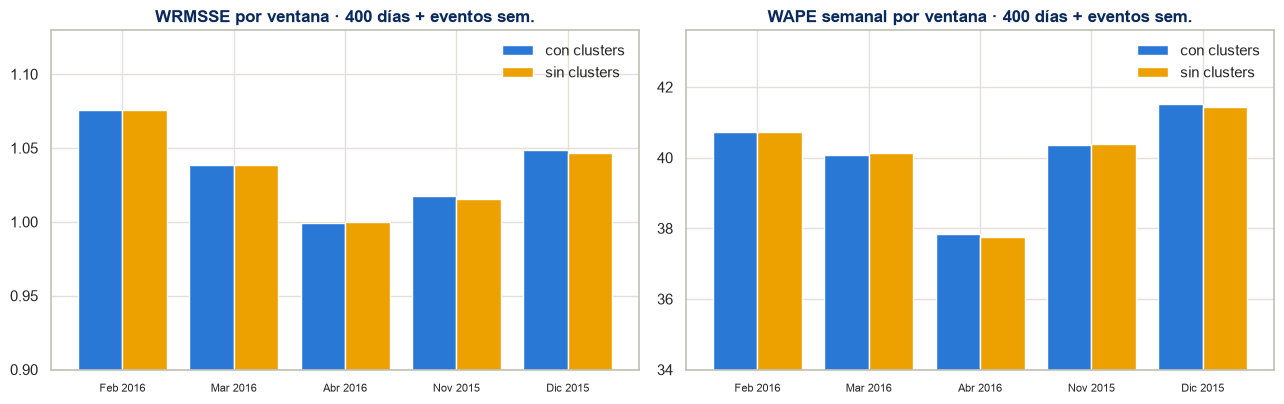

In [4]:
# Diferencia (sin clusters - con clusters): valores positivos = los clusters ayudan
dif = comp.pivot_table(index=['ventana', 'modelo'], columns='variante', values=['WRMSSE', 'WAPE semanal'])
d = pd.DataFrame({'Δ WRMSSE': dif['WRMSSE']['sin clusters'] - dif['WRMSSE']['con clusters'],
                  'Δ WAPE semanal (puntos)': dif['WAPE semanal']['sin clusters'] - dif['WAPE semanal']['con clusters']})
d['Δ WRMSSE (%)'] = d['Δ WRMSSE'] / dif['WRMSSE']['con clusters'] * 100
display(d.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, metrica in zip(axes, ['WRMSSE', 'WAPE semanal']):
    t = comp[comp['modelo'] == NOMBRE_CFG[configs[-1]]].pivot(index='ventana', columns='variante', values=metrica).reindex(orden_v)
    x = np.arange(len(t))
    ax.bar(x - 0.2, t['con clusters'], 0.4, color=DSMARKET_BLUE, label='con clusters')
    ax.bar(x + 0.2, t['sin clusters'], 0.4, color=DSMARKET_GOLD, label='sin clusters')
    ax.set_xticks(x); ax.set_xticklabels([v.split(' (')[0] for v in t.index], fontsize=8)
    ax.set_title(f'{metrica} por ventana · {NOMBRE_CFG[configs[-1]]}'); ax.legend(frameon=False)
    lo, hi = t.values.min(), t.values.max(); ax.set_ylim(lo * 0.9, hi * 1.05)
plt.tight_layout(); plt.show()

## 4. Modelo final sin clusters: media y percentil 90

El modelo final se reentrena sin `grupo_producto` en la última ventana (28 de marzo a 24 de abril de 2016, la que utiliza el notebook 04) para la predicción media y para el percentil 90. Se comparan las métricas de la sección 12 del notebook 03: WRMSSE, WAPE semanal, cobertura del p90 y pérdida pinball.

In [5]:
fin_sin = sc.modelo_final_sin_clusters(V_, P_, cs_, cal_, meta_, folds_)
fm_sin, fp_sin = fin_sin['media'], fin_sin['p90']
fm_con = np.load('cache_forecast/final_eval_media.npy'); fp_con = np.load('cache_forecast/final_eval_p90.npy')
s_, e_ = folds_[2]
y_ = V_[:, s_:e_].astype(np.float32); h_ = V_[:, :s_].astype(np.float32)
valido = ~np.isnan(P_[:, s_:e_])
def pinball(y, q, a=0.9):
    d = y - q
    return float(np.mean(np.maximum(a * d, (a - 1) * d)))
filas = {}
for nombre, fm, fp in [('con clusters', fm_con, fp_con), ('sin clusters', fm_sin, fp_sin)]:
    filas[nombre] = {'WRMSSE': fs.wrmsse(y_, fm, h_, P_[:, :s_]),
                     'WAPE semanal (%)': fw.wape(fw.a_semanas(y_), fw.a_semanas(fm)),
                     'cobertura p90 (%)': (y_[valido] <= fp[valido]).mean() * 100,
                     'pinball p90': pinball(y_[valido], fp[valido]),
                     'unidades media': fm[valido].sum(), 'unidades p90': fp[valido].sum()}
final_comp = pd.DataFrame(filas).T
final_comp.loc['diferencia (sin - con)'] = final_comp.loc['sin clusters'] - final_comp.loc['con clusters']
final_comp.round(4)

eval media: 1,151,452 unidades (139s)
eval p90: 2,630,372 unidades (380s)


,WRMSSE,WAPE semanal (%),cobertura p90 (%),pinball p90,unidades media,unidades p90
con clusters,0.9994,37.7801,89.4385,0.3055,1156731.25,2630360.0
sin clusters,1.0002,37.7552,89.4412,0.3059,1151452.00,2630372.0
diferencia (sin - con),0.0008,-0.0248,0.0027,0.0004,-5279.25,12.0


## 5. ¿Dónde se nota la ausencia de los clusters?

Se calcula el error semanal por grupo de producto. Los grupos se usan aquí solo para agrupar los resultados. Si los clusters aportaran información que el modelo no obtiene de otra forma, la diferencia se concentraría en los grupos más irregulares.

,con clusters,sin clusters,diferencia (puntos)
grupo,,,
Alta rotación diaria,34.65,34.59,-0.06
Pico de fin de semana,43.38,43.44,0.06
"Precio alto, pocas unidades",46.06,46.03,-0.04
Rotación baja sin picos,49.36,49.37,0.02
Pico de diciembre,61.17,61.14,-0.02
Venta esporádica con pico en eventos,71.12,71.68,0.56


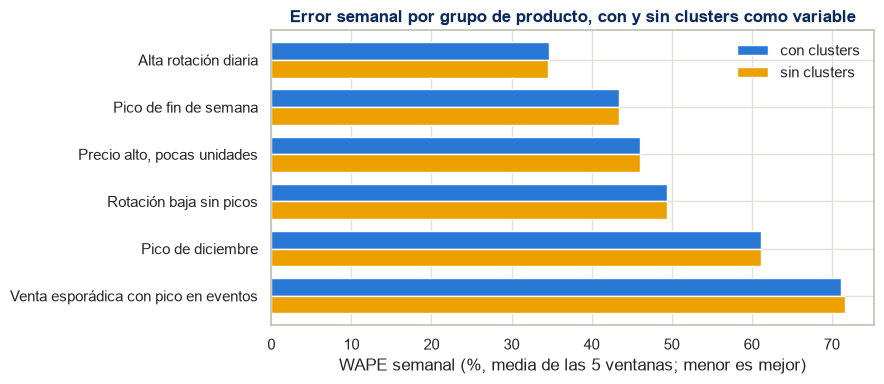

In [6]:
filas = []
cfg_f = configs[-1]
for nombre, (s_, e_) in V16.items():
    ys = fw.a_semanas(V_[:, s_:e_].astype(np.float32))
    pc = fw.a_semanas(fw.entrenar(cfg_f, nombre, (s_, e_), V_, P_, cs_, cal_, meta_, None)['pred'])
    ps = fw.a_semanas(res_sin[(cfg_f, nombre)]['pred'])
    for g, idx in meta_.groupby('nombre_grupo').indices.items():
        filas.append({'ventana': nombre, 'grupo': g, 'con clusters': fw.wape(ys[idx], pc[idx]),
                      'sin clusters': fw.wape(ys[idx], ps[idx])})
g = pd.DataFrame(filas)
tg = g.groupby('grupo')[['con clusters', 'sin clusters']].mean()
tg['diferencia (puntos)'] = tg['sin clusters'] - tg['con clusters']
tg = tg.sort_values('con clusters')
display(tg.round(2))
ax = tg[['con clusters', 'sin clusters']].plot.barh(figsize=(9, 4), color=[DSMARKET_BLUE, DSMARKET_GOLD], width=0.75)
ax.invert_yaxis(); ax.set_xlabel('WAPE semanal (%, media de las 5 ventanas; menor es mejor)'); ax.set_ylabel('')
ax.set_title('Error semanal por grupo de producto, con y sin clusters como variable')
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 6. Importancia de variables sin clusters

Sin `grupo_producto`, el modelo debe apoyarse en `item_id` y en las variables de comportamiento reciente (rezagos, medias móviles, fracción de ceros, desviación) para distinguir productos de perfil distinto.

In [7]:
imp_con = pd.concat([fw.entrenar(cfg_f, n, v, V_, P_, cs_, cal_, meta_, None)['importancia'] for n, v in V16.items()], axis=1).apply(lambda c: c / c.sum() * 100).mean(axis=1)
imp_sin = pd.concat([res_sin[(cfg_f, n)]['importancia'] for n in V16], axis=1).apply(lambda c: c / c.sum() * 100).mean(axis=1)
imp = pd.DataFrame({'con clusters (%)': imp_con, 'sin clusters (%)': imp_sin}).sort_values('sin clusters (%)', ascending=False)
display(imp.head(12).round(2))
print(f"Peso de grupo_producto en el modelo con clusters: {imp_con.get('grupo_producto', float('nan')):.2f} % de la importancia")

,con clusters (%),sin clusters (%)
rmean_28,47.17,50.27
rmean_91,25.87,22.97
rmean_364,9.33,8.96
item_id,5.37,5.78
rmean_7,5.44,5.10
rstd_28,1.55,1.77
lag_0,1.42,1.32
lag_4,0.50,0.63
is_weekend,0.38,0.48
month,0.40,0.43


Peso de grupo_producto en el modelo con clusters: 0.18 % de la importancia


## 7. Conclusión

In [8]:
# La conclusión se deriva de los resultados anteriores; no contiene cifras escritas a mano
w = comp[comp['modelo'] == NOMBRE_CFG[configs[-1]]].pivot(index='ventana', columns='variante', values='WRMSSE')
a = comp[comp['modelo'] == NOMBRE_CFG[configs[-1]]].pivot(index='ventana', columns='variante', values='WAPE semanal')
dw = (w['sin clusters'] - w['con clusters']) / w['con clusters'] * 100
da = a['sin clusters'] - a['con clusters']
gana_con = int((dw > 0).sum())
print(f"Modelo {NOMBRE_CFG[configs[-1]]}, 5 ventanas.")
print(f"  WRMSSE: la variante con clusters es mejor en {gana_con} de {len(dw)} ventanas; diferencia media {dw.mean():+.2f} % (sin respecto a con).")
print(f"  WAPE semanal: diferencia media {da.mean():+.2f} puntos (sin respecto a con).")
print(f"  Ventana de entrega (abr 2016): WRMSSE {final_comp.loc['con clusters','WRMSSE']:.4f} con clusters frente a {final_comp.loc['sin clusters','WRMSSE']:.4f} sin clusters;"
      f" cobertura p90 {final_comp.loc['con clusters','cobertura p90 (%)']:.1f} % frente a {final_comp.loc['sin clusters','cobertura p90 (%)']:.1f} %.")
if abs(dw.mean()) < 0.5 and abs(da.mean()) < 0.3:
    print("Lectura: diferencia inferior al ruido de validación; el aporte de los clusters al error de predicción es marginal.")
elif dw.mean() > 0:
    print("Lectura: los clusters mejoran la predicción de forma apreciable.")
else:
    print("Lectura: retirar los clusters mejora la predicción; la variable no aporta al modelo.")

Modelo 400 días + eventos sem., 5 ventanas.
  WRMSSE: la variante con clusters es mejor en 3 de 5 ventanas; diferencia media -0.05 % (sin respecto a con).
  WAPE semanal: diferencia media -0.01 puntos (sin respecto a con).
  Ventana de entrega (abr 2016): WRMSSE 0.9994 con clusters frente a 1.0002 sin clusters; cobertura p90 89.4 % frente a 89.4 %.
Lectura: diferencia inferior al ruido de validación; el aporte de los clusters al error de predicción es marginal.


**Cómo interpretar el resultado.**

- Si la diferencia es pequeña, no significa que el clustering carezca de utilidad. El modelo ya recibe `item_id` y variables de comportamiento reciente (medias, desviación, fracción de ceros), de modo que la información de los grupos queda en buena parte redundante *para predecir*.
- El valor de los grupos reside en **otros usos**: describir el catálogo a la dirección, fijar el nivel de servicio por segmento y la política de reposición (notebook 04, matriz ABC/XYZ) y analizar el error por tipo de producto. Esos usos no dependen de que la variable mejore el WRMSSE.
- Si la diferencia es favorable a los clusters, el aporte se concentraría en los grupos de demanda irregular (sección 5).

Los resultados se incorporarán a la memoria (apartado de forecasting) una vez ejecutado el notebook.